<a href="https://colab.research.google.com/github/malakabdelrahem/Machine--Learning-/blob/main/machine_learning_3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:

import numpy as np

x = np.array([0, 1, 2, 3], dtype=float)
y = np.array([1, 3, 4, 6], dtype=float)

X = np.c_[np.ones(len(x)), x]
theta = np.linalg.inv(X.T @ X) @ X.T @ y

print("E1 - Theta 0:", round(theta[0], 3))
print("E1 - Theta 1:", round(theta[1], 3))
print("E1 - Equation: y =", round(theta[0], 3), "+", round(theta[1], 3), "* x")

theta_old = 0
learning_rate = 0.2

gradient = 2 * (theta_old - 5)
theta_new = theta_old - learning_rate * gradient

print("\nE2 - New theta:", theta_new)


E1 - Theta 0: 1.1
E1 - Theta 1: 1.6
E1 - Equation: y = 1.1 + 1.6 * x

E2 - New theta: 2.0


In [ ]:
import numpy as np
from sklearn.linear_model import LinearRegression

X = np.array([[1], [2], [3], [4]])
y = np.array([2, 2, 4, 5])

def mse(y, yhat):
    return np.mean((y - yhat) ** 2)

model = LinearRegression()
model.fit(X, y)

yhat = model.predict(X)

print("Predictions:", np.round(yhat, 3))
print("Training MSE:", round(mse(y, yhat), 3))

Predictions: [1.6 2.7 3.8 4.9]
Training MSE: 0.175


In [ ]:
import numpy as np
from sklearn.linear_model import LinearRegression

X = np.array([[1], [2], [3], [4]])
y = np.array([2, 2, 4, 5])

def mse(y, yhat):
    return np.mean((y - yhat) ** 2)

model = LinearRegression()
model.fit(X, y)

yhat = model.predict(X)

print("Predictions:", np.round(yhat, 3))
print("Training MSE:", round(mse(y, yhat), 3))

Predictions: [1.6 2.7 3.8 4.9]
Training MSE: 0.175


Normal Equation MSE: 0.5559
Gradient Descent MSE (0.01): 0.5672
Gradient Descent MSE (0.05): 0.5562


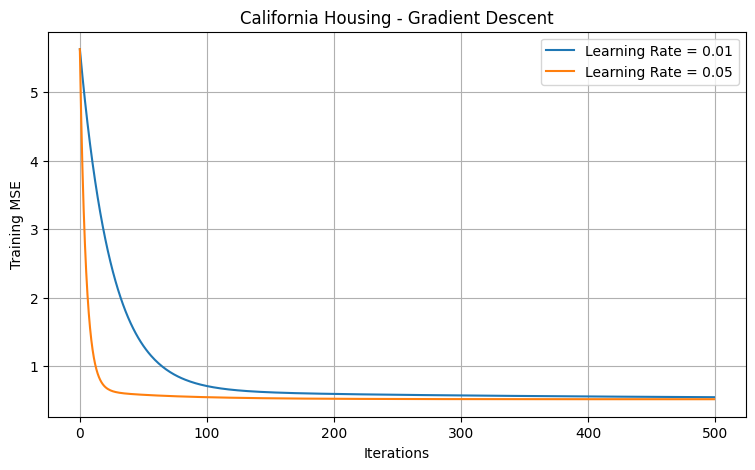

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error

# Load dataset

data = fetch_california_housing()
X = data.data
y = data.target

# Split data

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# Feature scaling

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

# Add intercept

X_train_b = np.c_[np.ones(len(X_train)), X_train]
X_test_b = np.c_[np.ones(len(X_test)), X_test]

# Normal Equation

theta_ne = np.linalg.pinv(X_train_b) @ y_train
pred_ne = X_test_b @ theta_ne

print("Normal Equation MSE:", round(
    mean_squared_error(y_test, pred_ne), 4
))

# Batch Gradient Descent

def batch_gradient_descent(X, y, learning_rate, iterations):
    m, n = X.shape
    theta = np.zeros(n)
    costs = []

    for _ in range(iterations):
        predictions = X @ theta
        errors = predictions - y

        costs.append(np.mean(errors ** 2))

        gradients = (2 / m) * (X.T @ errors)
        theta -= learning_rate * gradients

    return theta, costs


iterations = 500

theta1, costs1 = batch_gradient_descent(
    X_train_b, y_train, 0.01, iterations
)

theta2, costs2 = batch_gradient_descent(
    X_train_b, y_train, 0.05, iterations
)

# Evaluate

pred1 = X_test_b @ theta1
pred2 = X_test_b @ theta2

print("Gradient Descent MSE (0.01):",
      round(mean_squared_error(y_test, pred1), 4))

print("Gradient Descent MSE (0.05):",
      round(mean_squared_error(y_test, pred2), 4))

# Plot cost

plt.figure(figsize=(9, 5))
plt.plot(costs1, label="Learning Rate = 0.01")
plt.plot(costs2, label="Learning Rate = 0.05")
plt.xlabel("Iterations")
plt.ylabel("Training MSE")
plt.title("California Housing - Gradient Descent")
plt.legend()
plt.grid(True)
plt.show()